In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Notebook 位于 notebooks/ 目录
data_path = Path("../data/processed/monthly_business_performance.csv")

df = pd.read_csv(data_path)

df["order_month"] = pd.to_datetime(
    df["order_month"],
    format="%Y-%m"
)

df = df.sort_values("order_month").reset_index(drop=True)

print(df.shape)
display(df.head())

(20, 9)


,order_month,total_orders,valid_delivered_orders,delivered_gmv,aov,orders_mom_pct,valid_orders_mom_pct,gmv_mom_pct,aov_mom_pct
0,2017-01-01,800,750,111798.36,149.06,NaN,NaN,NaN,NaN
1,2017-02-01,1780,1653,234223.40,141.70,NaN,NaN,NaN,NaN
2,2017-03-01,2682,2546,359198.85,141.08,50.67,54.02,53.36,-0.43
3,2017-04-01,2404,2303,340669.68,147.92,-10.37,-9.54,-5.16,4.85
4,2017-05-01,3700,3546,489338.25,138.00,53.91,53.97,43.64,-6.71


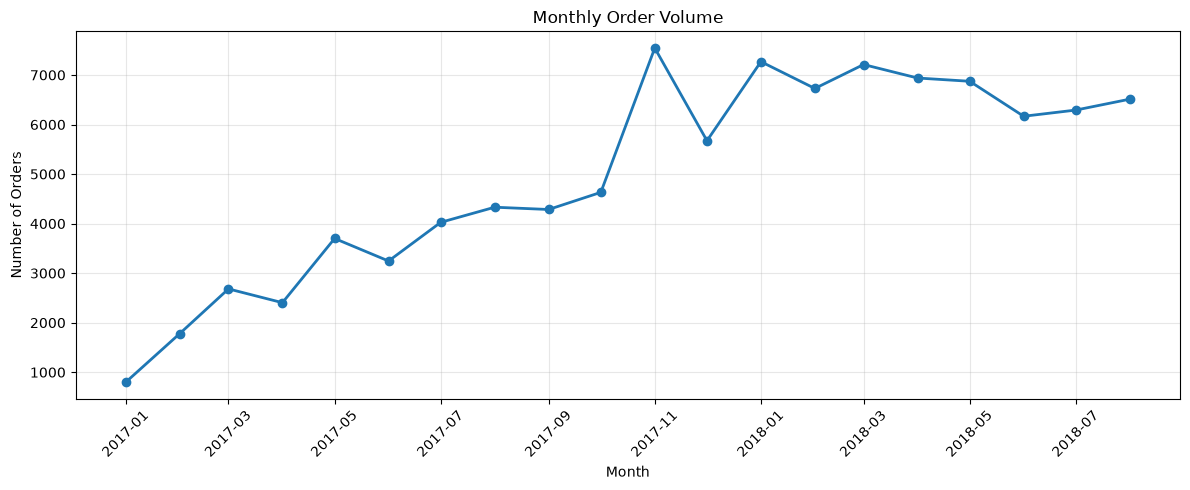

In [2]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["order_month"],
    df["total_orders"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Order Volume")
plt.xlabel("Month")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../reports/figures/monthly_orders.png",
    dpi=300
)

plt.show()

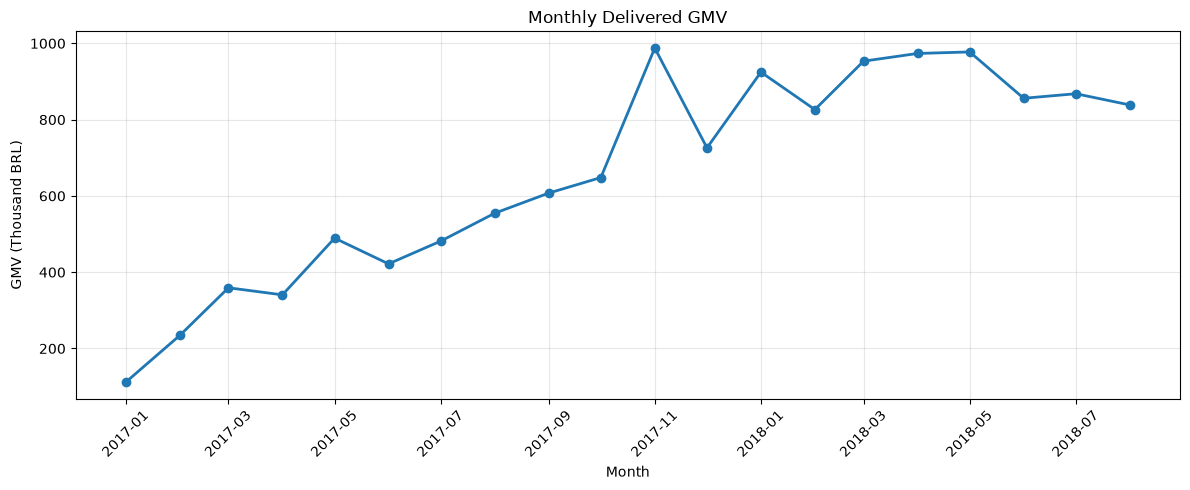

In [3]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["order_month"],
    df["delivered_gmv"] / 1000,
    marker="o",
    linewidth=2
)

plt.title("Monthly Delivered GMV")
plt.xlabel("Month")
plt.ylabel("GMV (Thousand BRL)")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../reports/figures/monthly_gmv.png",
    dpi=300
)

plt.show()

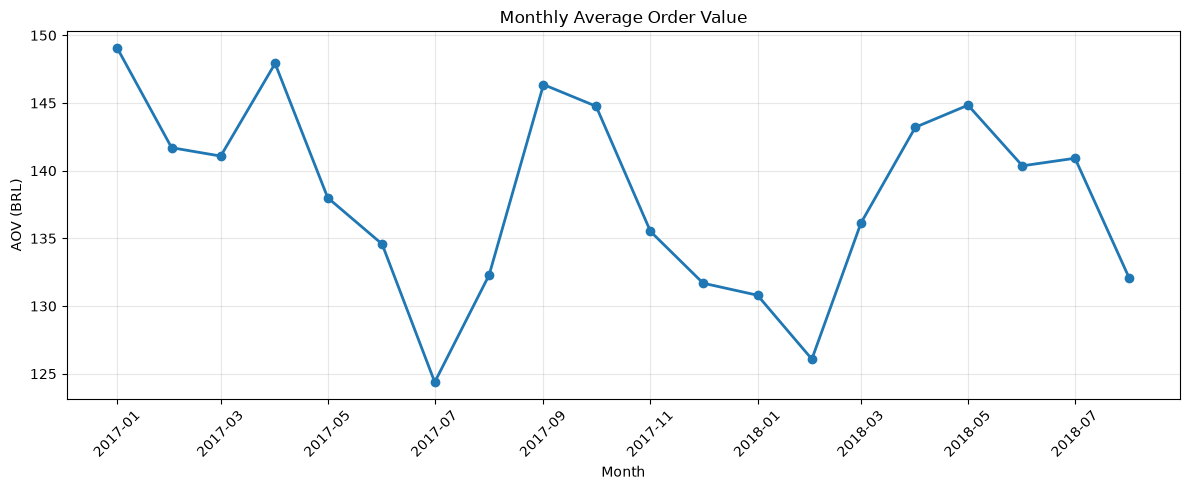

In [4]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["order_month"],
    df["aov"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Average Order Value")
plt.xlabel("Month")
plt.ylabel("AOV (BRL)")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../reports/figures/monthly_aov.png",
    dpi=300
)

plt.show()

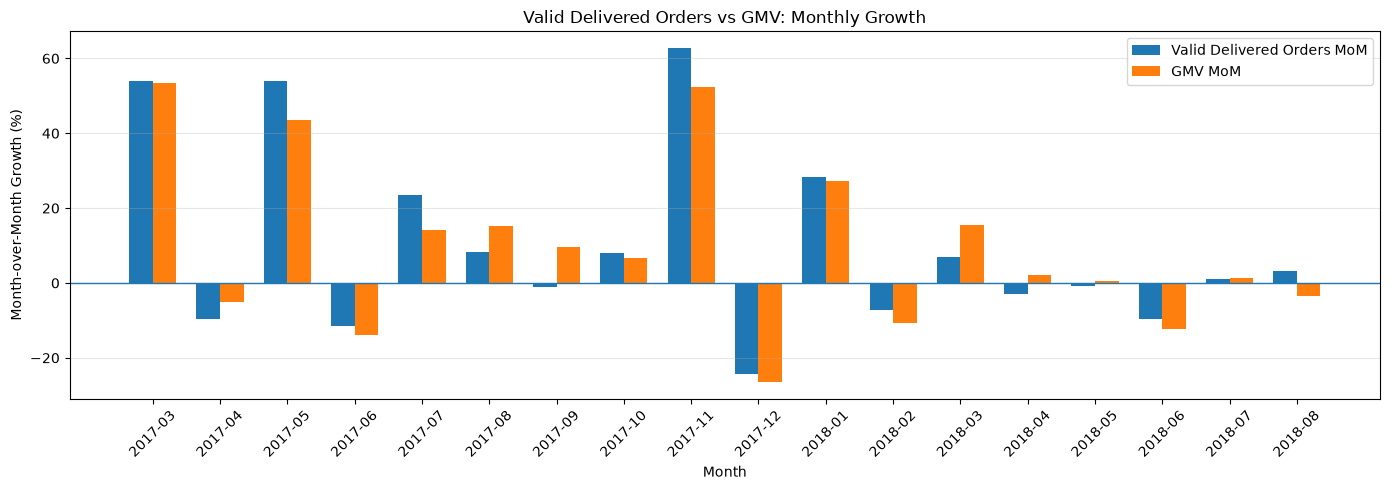

In [9]:
# 去除不参与环比分析的月份
mom_df = df.dropna(
    subset=["orders_mom_pct", "gmv_mom_pct"]
).copy()

x = np.arange(len(mom_df))
width = 0.35

plt.figure(figsize=(14, 5))

plt.bar(
    x - width / 2,
    mom_df["valid_orders_mom_pct"],
    width,
    label="Valid Delivered Orders MoM"
)

plt.bar(
    x + width / 2,
    mom_df["gmv_mom_pct"],
    width,
    label="GMV MoM"
)

plt.axhline(0, linewidth=1)

plt.xticks(
    x,
    mom_df["order_month"].dt.strftime("%Y-%m"),
    rotation=45
)

plt.title("Valid Delivered Orders vs GMV: Monthly Growth")
plt.xlabel("Month")
plt.ylabel("Month-over-Month Growth (%)")

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../reports/figures/monthly_growth_comparison.png",
    dpi=300
)

plt.show()

## 经营表现分析总结

### 1. 经营规模

2017 年至 2018 年中期，平台月度订单规模总体呈增长趋势，2018 年逐渐进入相对平稳的波动区间。

2017 年 11 月订单量达到 7,544 单，已送达商品交易额达到 R$987,765.37，均为分析期间最高值。

2018 年 1—8 月，月度订单量主要维持在 6,000～7,300 单，交易规模较 2017 年初明显扩大。

### 2. 增长驱动

平台商品交易额变化主要受有效已送达订单数量和客单价（AOV）共同影响。

2017 年 11 月：
- 有效已送达订单量环比增长 62.77%。
- 商品交易额环比增长 52.37%。
- AOV 环比下降 6.39%。

说明该月交易额增长主要由订单规模扩大推动，而非客单价提高。

2017 年 9 月：
- 有效已送达订单量环比下降 1.03%。
- AOV 环比增长 10.64%。
- 商品交易额环比增长 9.50%。

说明客单价提升能够在订单数量下降时推动交易额增长。

### 3. 客单价变化

分析期间，AOV 存在明显波动，未呈现持续上升趋势。

- 2017 年 7 月：R$124.38，为分析期间最低值。
- 2017 年 9 月：R$146.36，较上月明显回升。
- 2018 年 5 月：R$144.84，处于相对较高水平。
- 2018 年 8 月：R$132.04，环比下降 6.31%。

2018 年 8 月，有效已送达订单量环比增长 3.12%，但商品交易额下降 3.38%。

说明订单规模扩大不一定能够带来交易额增长，客单价变化同样具有重要影响。

后续需要结合商品品类及价格结构，进一步调查 AOV 波动的可能原因。

### 4. 经营风险与异常现象

**（1）短期交易高峰**

2017 年 11 月订单量环比增长 62.90%，12 月则下降 24.80%。

可能存在季节性需求或促销活动影响，但目前缺少相关数据，无法确定具体原因。

**（2）订单增长与交易额背离**

2018 年 8 月总订单量环比增长 3.50%，商品交易额却下降 3.38%。

进一步分析发现，AOV 下降是交易额减少的重要因素。

**（3）订单取消率变化**

2018 年 8 月取消率达到 1.29%，为主要分析区间最高值。

该现象值得关注，但考虑到数据末期可能存在履约观察期不足的问题，暂时不能直接判断平台经营状况恶化。

### 5. 综合业务结论

1. 平台在分析期间实现了明显的交易规模扩张，但月度增长并不均匀，2018 年订单规模趋于相对稳定。

2. 商品交易额增长具有不同的驱动结构，既可能来自订单数量增加，也可能来自客单价提高。

3. 单纯使用订单量衡量经营表现存在局限，应结合 GMV、AOV 及订单状态等指标综合评价。

4. 客单价在不同月份存在较明显波动，商品品类结构及商品价格分布可能是重要影响因素，值得进一步研究。

5. 后续商品与地区分析应重点关注头部品类贡献、销售集中度及不同商品结构下的客单价差异。

### 6. 分析局限

- 数据主要采用 2017 年 1 月至 2018 年 8 月的历史交易记录，首尾月份存在覆盖或观察期限制。
- 商品交易额采用已送达订单的商品金额，不含运费，不等同于平台实际收入或利润。
- 缺少营销活动、促销费用和流量数据，无法直接解释订单增长或下降的具体原因。
- 不同月份的商品结构可能发生变化，目前尚未完成相关验证。
- 按购买月份统计订单最终状态，临近数据末尾的月份可能受到订单履约观察期不足的影响。
- 当前分析主要为描述性分析，不能据此建立因果关系。